# CT1 – Task 3: RNN Sequence Modeling
## Character-Level Language Modeling of Jane Austen's Novels with Vanilla RNN, GRU and LSTM

**Course:** CSE638 Deep Learning, Daffodil International University
**Group:** Recurrent Minds

| Member | Student ID |
|---|---|
| Shafin Ahmed | 262-25-035 |
| Zohir Rayhan | 262-25-036 |
| Sheikh Ajwad | 262-25-337 |

**Task (from the assignment sheet):** *Train an RNN (vanilla, GRU, simple LSTM) for character-level or word-level language
modeling / text generation … compare different RNN variants, sequence length effects, sampling strategies, and perplexity.*

**Research questions**
1. **RQ1 – Cell type:** how much do gated cells (GRU, LSTM) improve on a vanilla RNN at equal width and compute?
2. **RQ2 – Sequence length:** how does the BPTT window (32–256 characters) affect quality and cost?
3. **RQ3 – Capacity:** how do hidden size and depth trade off against accuracy and training time?
4. **RQ4 – Baseline:** do neural models beat a strong smoothed character n-gram model?
5. **RQ5 – Sampling:** how do greedy, temperature, top-k and nucleus decoding change the generated text?

> The heavy training runs are executed by `run_experiments.py` (all ten runs, ~3 CPU-hours) and saved to `results/`.
> This notebook re-uses the same modules in `src/`, performs the full data analysis live, loads the saved runs,
> and produces every table and figure used in the report. Set `RETRAIN = True` to retrain from scratch.

In [1]:
import sys, json, math, time, textwrap
from pathlib import Path
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

ROOT = Path.cwd(); sys.path.insert(0, str(ROOT))
from src.data import build_corpus, encode, BOOKS
from src.models import CharRNN, n_params
from src.train import Config, evaluate, LN2
from src import analysis as A
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
torch.set_num_threads(4); torch.manual_seed(42)
RETRAIN = False
print("torch", torch.__version__, "| threads", torch.get_num_threads())

torch 2.15.0+cpu | threads 4


## 1. Data acquisition and cleaning
Six complete novels by Jane Austen are downloaded from Project Gutenberg (public domain). A single-author corpus keeps
style consistent, so differences between models reflect modeling ability rather than domain shift.

**Cleaning pipeline (`src/data.py`)**
1. strip Gutenberg licence header/footer; 2. normalise line endings and Unicode punctuation to ASCII;
3. remove `[Illustration]` markup and `_italic_` underscores; 4. un-wrap hard line breaks inside paragraphs;
5. drop characters that occur fewer than 20 times (e.g. `£`, `æ`).

**Split:** every novel is split *contiguously* 90 % / 5 % / 5 % into train / validation / test, so each split contains all
six novels but no passage appears in two splits (no leakage from overlapping windows).

In [2]:
texts, stoi, meta, cleaned = build_corpus(ROOT / "data")
itos = {i: c for c, i in stoi.items()}
print("Vocabulary size:", meta["vocab_size"])
print("Vocabulary:", repr("".join(meta["vocab"])))
print("Rare characters removed:", meta["removed_rare"])
corpus = A.corpus_table(meta, cleaned); display(corpus)
display(A.split_table(meta))
print(cleaned[1342][:600])

Vocabulary size: 75
Vocabulary: '\n !"\'(),-.0123456789:;?ABCDEFGHIJKLMNOPQRSTUVWXY]abcdefghijklmnopqrstuvwxyz'
Rare characters removed: {'Z': 2, '*': 18, '[': 3, 'œ': 3, '&': 17, '£': 6, '/': 18, 'æ': 1}


,Book,Gutenberg ID,Raw chars,Clean chars,Removed (%),Words,Unique words,Paragraphs
0,Pride and Prejudice,1342,748167,713615,4.6,127184,6849,2281
1,Emma,158,899675,882425,1.9,161212,7278,2382
2,Sense and Sensibility,161,689951,670271,2.9,120084,6441,1864
3,Mansfield Park,141,903258,882706,2.3,160669,7921,1846
4,Northanger Abbey,121,453327,433687,4.3,77826,6111,1063
5,Persuasion,105,484132,464718,4.0,83713,5879,1040
6,TOTAL,,4178510,4047422,3.1,730688,14466,10476


,Split,Characters,Share (%)
0,train,3642687,90.0
1,val,202381,5.0
2,test,202384,5.0


PRIDE. and PREJUDICE

by Jane Austen,

with a Preface by George Saintsbury and Illustrations by Hugh Thomson

Ruskin 156. Charing House. Cross Road.

London George Allen.

CHISWICK PRESS:--CHARLES WHITTINGHAM AND CO. TOOKS COURT, CHANCERY LANE, LONDON.

PREFACE.

Walt Whitman has somewhere a fine and just distinction between "loving by allowance" and "loving with personal love." This distinction applies to books as well as to men and women; and in the case of the not very numerous authors who are the objects of the personal affection, it brings a curious consequence with it. There is much more


## 2. Exploratory data analysis

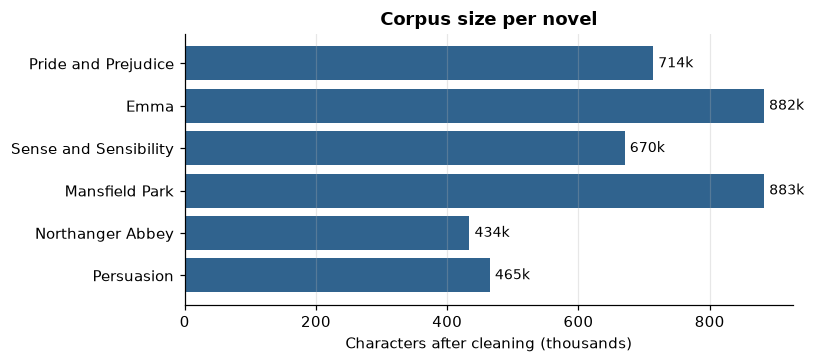

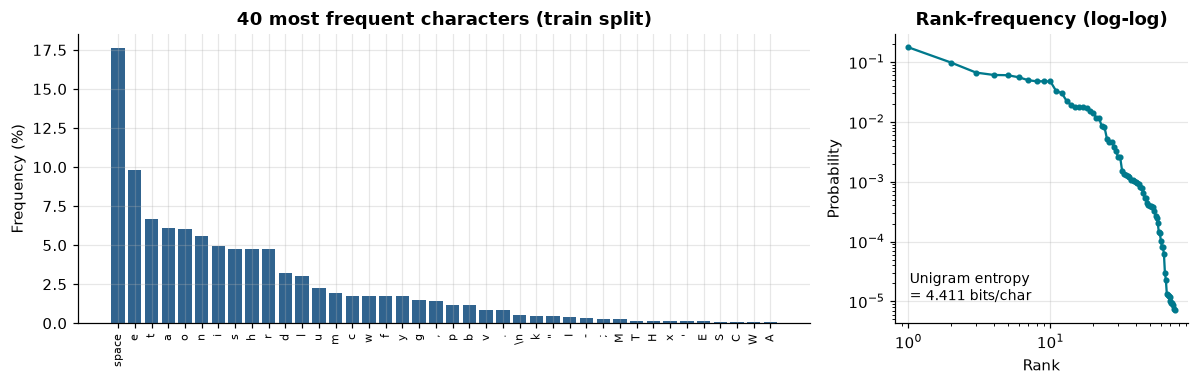

Unigram entropy: 4.411 bits/char  (upper bound a model must beat; uniform over 75 chars = 6.229)
Character classes (%): {'letter': 78.24, 'punctuation': 3.6, 'space/newline': 18.15, 'digit': 0.01}


In [3]:
A.fig_book_sizes(corpus); plt.show()
fig, H, classes = A.fig_char_freq(texts["train"]); plt.show()
print(f"Unigram entropy: {H:.3f} bits/char  (upper bound a model must beat; uniform over 75 chars = {math.log2(75):.3f})")
print("Character classes (%):", classes)

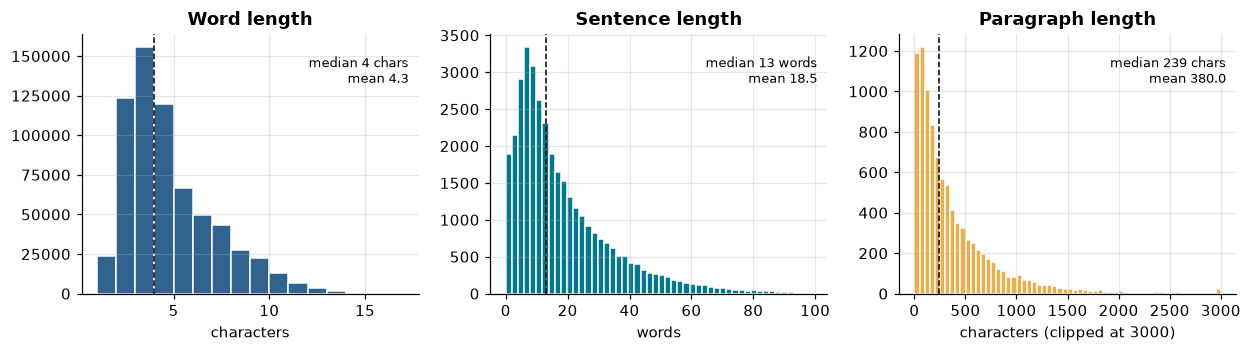

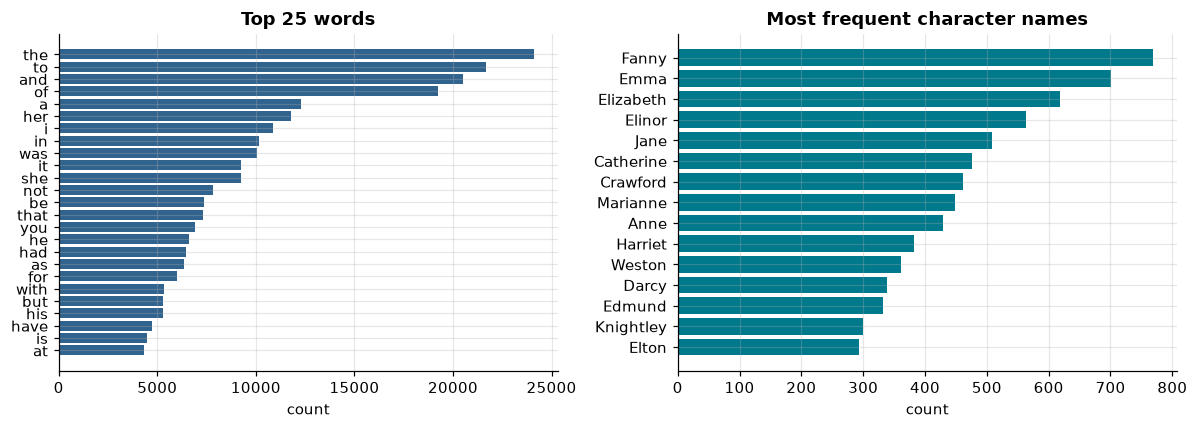

{'word_len_mean': np.float64(4.34), 'sent_len_median': 13.0, 'sent_len_mean': np.float64(18.5), 'para_len_median': 239.0, 'para_len_p95': 1192.2, 'n_sentences': 35585, 'vocab_words': 14006, 'hapax': 4630, 'hapax_pct': 33.06, 'top_word': ('the', 24118)}


In [4]:
fig, L = A.fig_lengths(texts["train"]); plt.show()
fig, W = A.fig_top_words(texts["train"]); plt.show()
print({k: (round(v, 2) if isinstance(v, float) else v) for k, v in {**L, **W}.items()})

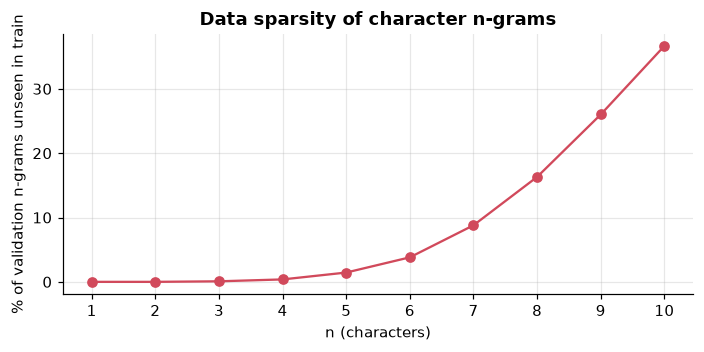

,n,unseen_val_ngrams_pct,distinct_train_ngrams
0,1,0.000000,75
1,2,0.000000,1592
2,3,0.083011,11088
3,4,0.377019,46496
4,5,1.445816,138214
5,6,3.811698,317172
6,7,8.792501,588835
7,8,16.308671,938753
8,9,26.014320,1335251
9,10,36.667704,1735826


In [5]:
fig, sparsity = A.fig_ngram_coverage(texts["train"], texts["val"]); plt.show()
display(sparsity)

**EDA findings**
* The cleaned corpus has 4.05 M characters (0.73 M words, 14.5 k distinct word types); cleaning removed only 3.1 %.
  75 distinct characters remain: letters 78.2 %, space/newline 18.2 %, punctuation 3.6 %, digits 0.01 %.
* The unigram entropy (4.41 bits/char) is the score of a model that ignores context; every useful model must go far below it.
* Mean word length is 4.3 characters, so a 128-character window spans ~25 words. Sentences have a median of 13 and a
  mean of 18.5 words (long tail); paragraphs have a median of 239 characters, but the 95th percentile is 1 192 characters,
  so long-range structure (quotations, dialogue turns) exists — the motivation for testing longer BPTT windows.
* One third of the training word types (33 %) are hapax legomena (seen once): a word-level model would struggle
  with rare words, while a character model can still spell them.
* Sparsity: 16.3 % of validation 8-grams and 36.7 % of 10-grams never occur in training. Count-based n-gram models
  therefore run out of usable context after ~6–7 characters, which is the core argument for recurrent models that
  generalise over long histories.

## 3. Workflow
```
Gutenberg (6 novels) ─► clean & normalise ─► 90/5/5 contiguous split ─► char vocabulary (75)
        │                                                                     │
        ▼                                                                     ▼
   EDA (stats, sparsity)                    random windows (seq_len+1) ─► CharRNN {RNN|GRU|LSTM}
                                                                              │  AdamW, warm-up + cosine LR,
                                                                              │  grad-clip 1.0, dropout 0.2
                                                                              ▼
                          stateful evaluation on val (model selection) / test (final) ─► BPC, perplexity
                                                                              │
                                              n-gram baseline ◄───────────────┤
                                                                              ▼
                                         sampling study (greedy / temperature / top-k / nucleus)
```

## 4. Models
All neural models share one class (`src/models.py`): **Embedding(75→64) → stacked recurrent layers → Dropout → Linear(→75)**.
Only the recurrent cell or its size changes between runs.

* **Vanilla RNN:** $h_t=\tanh(W_x x_t + W_h h_{t-1} + b)$ – no gating, gradients vanish/explode over long spans.
* **GRU:** update gate $z_t$ and reset gate $r_t$; $h_t=(1-z_t)\odot h_{t-1}+z_t\odot\tilde h_t$ (3 weight blocks).
* **LSTM:** input/forget/output gates and a separate cell state $c_t=f_t\odot c_{t-1}+i_t\odot\tilde c_t$ (4 weight blocks).

**Training setup (identical for every run):** AdamW (lr 2e-3), 100-step warm-up + cosine decay, 2 500 steps,
8 192 characters per batch (batch = 8192 / seq_len, so each step costs the same compute regardless of sequence length),
gradient clipping at 1.0, dropout 0.2, seed 42. The checkpoint with the best validation loss is kept.

**Metrics:** cross-entropy in bits per character (**BPC** = nats / ln 2) and character **perplexity** = e^loss.
Evaluation is stateful (hidden state carried across 256-char chunks), so scores are comparable across training sequence lengths.

In [6]:
rows = []
for cell in ("rnn", "gru", "lstm"):
    m = CharRNN(meta["vocab_size"], cell)
    rows.append({"Cell": cell.upper(), "Embedding": 75 * 64, "Recurrent": sum(p.numel() for p in m.rnn.parameters()),
                 "Output": sum(p.numel() for p in m.head.parameters()), "Total": n_params(m)})
display(A._tab(pd.DataFrame(rows), "model_params"))
print(CharRNN(meta["vocab_size"], "lstm"))

,Cell,Embedding,Recurrent,Output,Total
0,RNN,4800,214016,19275,238091
1,GRU,4800,642048,19275,666123
2,LSTM,4800,856064,19275,880139


CharRNN(
  (embed): Embedding(75, 64)
  (rnn): LSTM(64, 256, num_layers=2, batch_first=True, dropout=0.2)
  (drop): Dropout(p=0.2, inplace=False)
  (head): Linear(in_features=256, out_features=75, bias=True)
)


## 5. Experiments
| ID | Question | Runs |
|---|---|---|
| E1 | cell type | RNN, GRU, LSTM — hidden 256, 2 layers, seq 128 |
| E2 | sequence length | LSTM with seq 32, 64, 128 (=E1_lstm), 256 |
| E3 | capacity / depth | LSTM hidden 128, 256, 384; layers 1, 2, 3 |
| E4 | non-neural baseline | Witten-Bell character n-gram, order 3 / 5 / 7 |
| E5 | sampling | 7 decoding strategies on the best model |

In [7]:
if RETRAIN:
    import subprocess; subprocess.run([sys.executable, "run_experiments.py", "--workers", "3", "--threads", "4"], check=True)
runs = A.load_runs()
tab = A.results_table(runs)
ngram = pd.DataFrame(json.loads((ROOT / "results/ngram_baseline.json").read_text()))
display(tab)
display(ngram.round(4))

,Run,Experiment,Cell,Hidden,Layers,Seq len,Batch,Params (M),Train loss,Val BPC,Test BPC,Test PPL,Gen. gap (BPC),Train time (min)
0,E1_gru,E1,GRU,256,2,128,64,0.666,1.1975,1.6107,1.5850,3.000,-0.1169,45.4
1,E1_lstm,E1,LSTM,256,2,128,64,0.880,1.3004,1.7516,1.7261,3.308,-0.1244,36.9
2,E1_rnn,E1,RNN,256,2,128,64,0.238,1.3578,1.7907,1.7661,3.401,-0.1683,20.5
3,E2_lstm_seq256,E2,LSTM,256,2,256,32,0.880,1.2909,1.7471,1.7203,3.295,-0.1153,56.1
4,E2_lstm_seq32,E2,LSTM,256,2,32,256,0.880,1.3668,1.7611,1.7362,3.332,-0.2108,33.0
5,E2_lstm_seq64,E2,LSTM,256,2,64,128,0.880,1.3267,1.7567,1.7313,3.320,-0.1573,43.2
6,E3_lstm_L1,E3,LSTM,256,1,128,64,0.354,1.3601,1.8513,1.8297,3.555,-0.1110,25.3
7,E3_lstm_L3,E3,LSTM,256,3,128,64,1.406,1.3751,1.8425,1.8176,3.525,-0.1413,71.0
8,E3_lstm_h128,E3,LSTM,128,2,128,64,0.246,1.5390,2.0468,2.0267,4.075,-0.1735,19.5
9,E3_lstm_h384,E3,LSTM,384,2,128,64,1.908,1.1876,1.6234,1.5995,3.030,-0.0900,83.6


,model,order,val_bpc,test_bpc,test_ppl,fit_s,n_contexts
0,Witten-Bell 3-gram,3,2.0783,2.0576,4.1630,4.6297,12755
1,Witten-Bell 5-gram,5,1.6813,1.6529,3.1446,13.3616,197465
2,Witten-Bell 7-gram,7,1.7466,1.7031,3.2559,22.9253,1103472


### 5.1 E1 – Vanilla RNN vs GRU vs LSTM

,Cell,Params (M),Val BPC,Test BPC,Test PPL,Train time (min)
0,RNN,0.238,1.7907,1.7661,3.401,20.5
1,GRU,0.666,1.6107,1.5850,3.000,45.4
2,LSTM,0.880,1.7516,1.7261,3.308,36.9


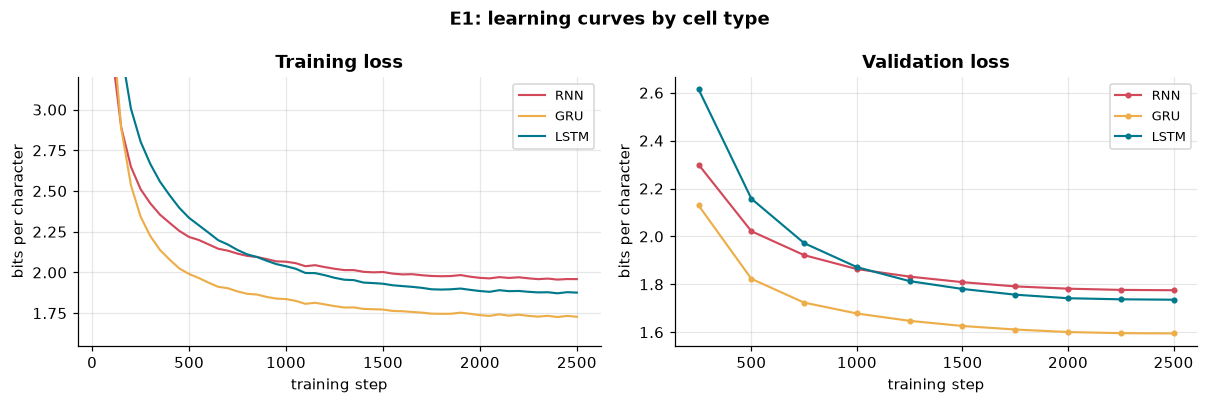

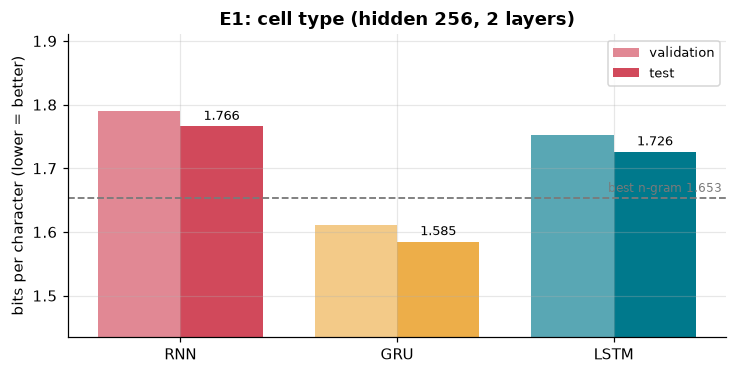

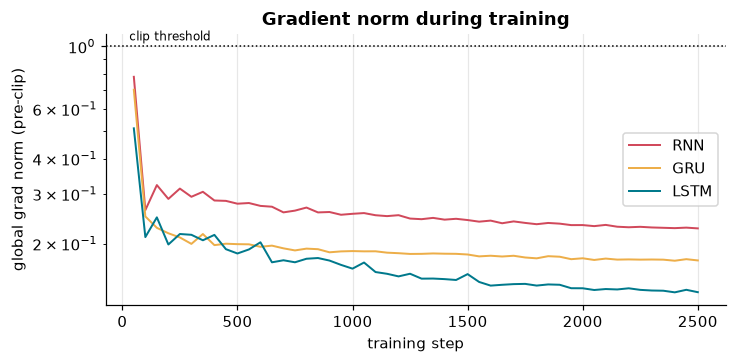

In [8]:
best_ng = ngram.test_bpc.min()
e1 = tab[tab.Experiment == "E1"].set_index("Cell").loc[["RNN", "GRU", "LSTM"]].reset_index()
display(e1[["Cell", "Params (M)", "Val BPC", "Test BPC", "Test PPL", "Train time (min)"]])
A.fig_curves(runs, ["E1_rnn", "E1_gru", "E1_lstm"], ["RNN", "GRU", "LSTM"], "E1: learning curves by cell type",
             "e1_learning_curves", colors=[A.PALETTE[c] for c in ("rnn", "gru", "lstm")]); plt.show()
A.fig_bar(e1, "Cell", "E1: cell type (hidden 256, 2 layers)", "e1_bpc_bar", best_ng,
          colors=[A.PALETTE[c] for c in ("rnn", "gru", "lstm")]); plt.show()
A.fig_grad_norms(runs); plt.show()

### 5.2 E2 – Effect of BPTT sequence length (LSTM)

,Run,Seq len,Batch,Val BPC,Test BPC,Train time (min)
0,E2_lstm_seq32,32,256,1.7611,1.7362,33.0
1,E2_lstm_seq64,64,128,1.7567,1.7313,43.2
2,E1_lstm,128,64,1.7516,1.7261,36.9
3,E2_lstm_seq256,256,32,1.7471,1.7203,56.1


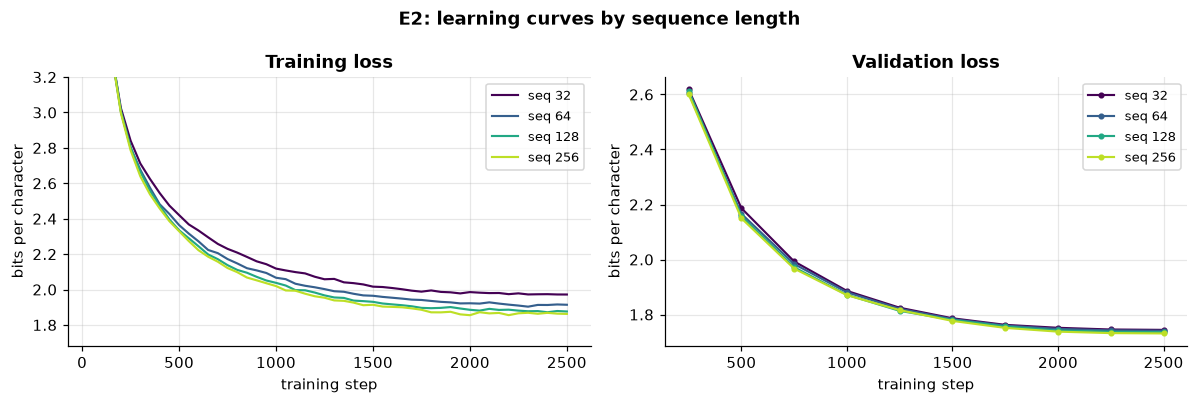

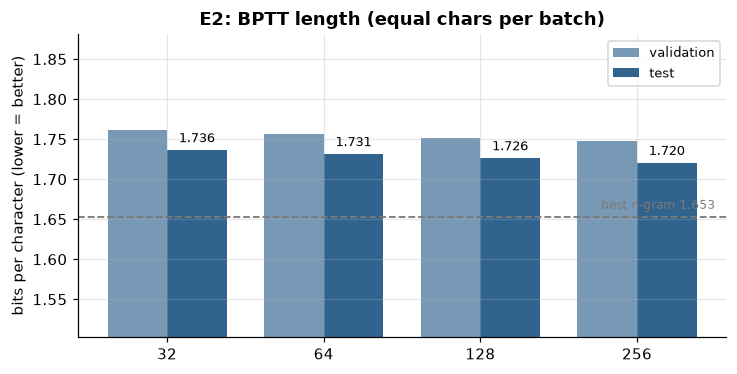

In [9]:
e2names = ["E2_lstm_seq32", "E2_lstm_seq64", "E1_lstm", "E2_lstm_seq256"]
e2 = tab.set_index("Run").loc[e2names].reset_index()
display(e2[["Run", "Seq len", "Batch", "Val BPC", "Test BPC", "Train time (min)"]])
A.fig_curves(runs, e2names, ["seq 32", "seq 64", "seq 128", "seq 256"], "E2: learning curves by sequence length",
             "e2_learning_curves"); plt.show()
A.fig_bar(e2, "Seq len", "E2: BPTT length (equal chars per batch)", "e2_bpc_bar", best_ng); plt.show()

### 5.3 E3 – Capacity and depth (LSTM)

,Run,Hidden,Params (M),Train loss,Val BPC,Test BPC,Train time (min)
0,E3_lstm_h128,128,0.246,1.5390,2.0468,2.0267,19.5
1,E1_lstm,256,0.880,1.3004,1.7516,1.7261,36.9
2,E3_lstm_h384,384,1.908,1.1876,1.6234,1.5995,83.6


,Run,Layers,Params (M),Train loss,Val BPC,Test BPC,Train time (min)
0,E3_lstm_L1,1,0.354,1.3601,1.8513,1.8297,25.3
1,E1_lstm,2,0.880,1.3004,1.7516,1.7261,36.9
2,E3_lstm_L3,3,1.406,1.3751,1.8425,1.8176,71.0


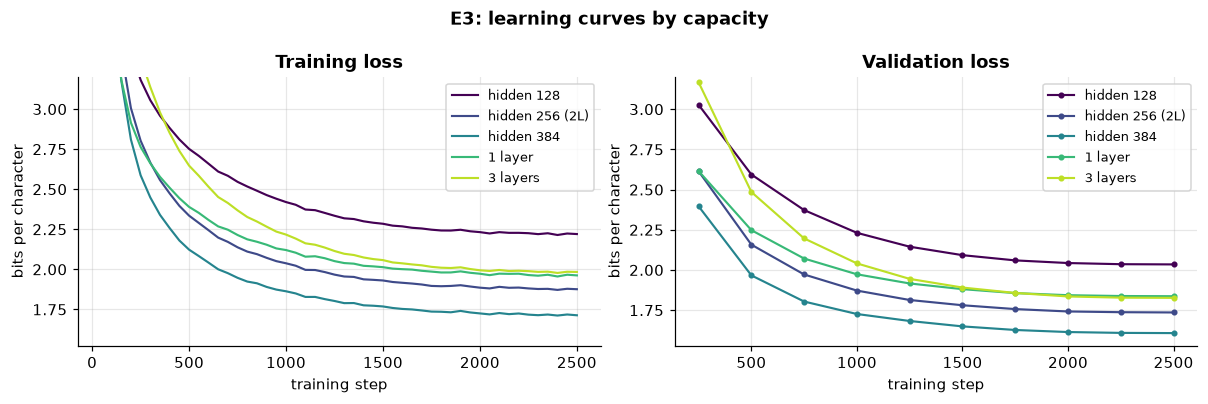

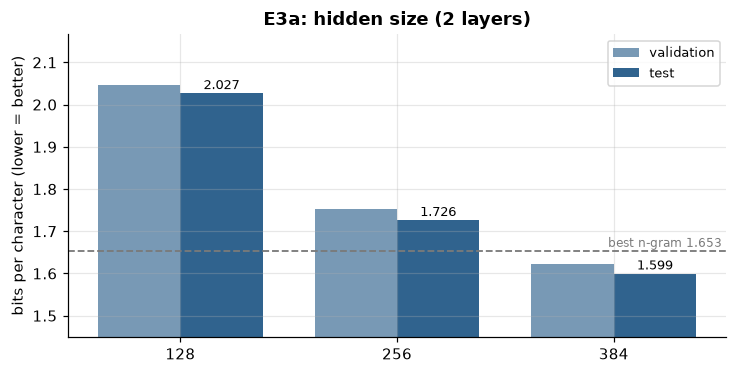

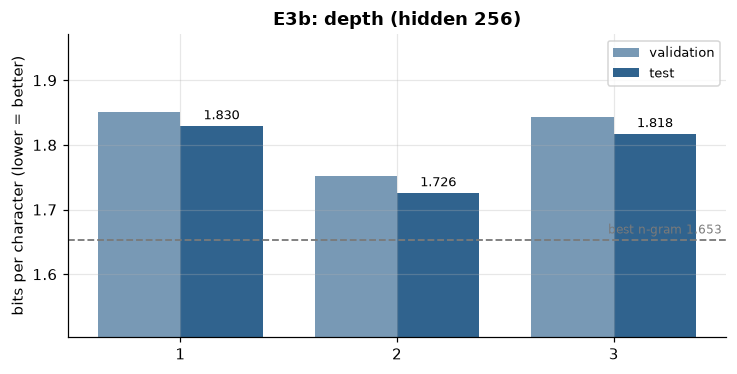

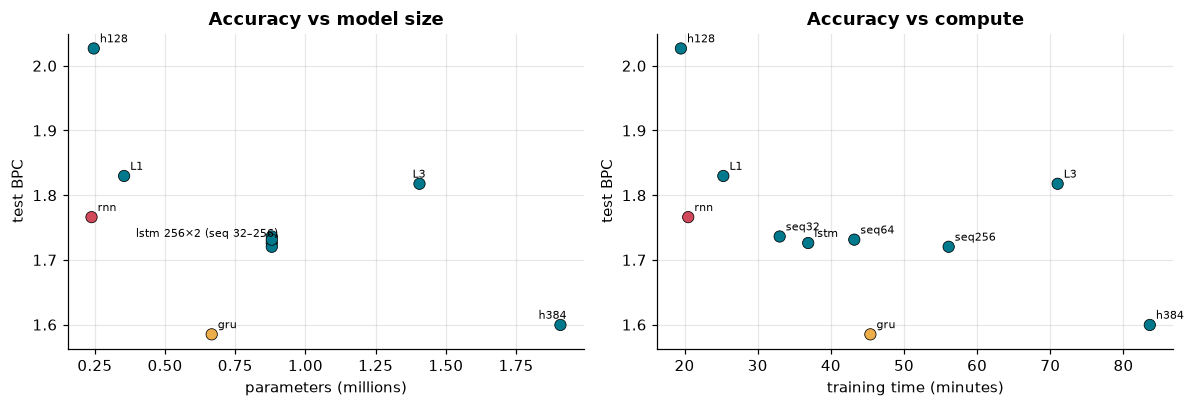

In [10]:
e3h = tab.set_index("Run").loc[["E3_lstm_h128", "E1_lstm", "E3_lstm_h384"]].reset_index()
e3l = tab.set_index("Run").loc[["E3_lstm_L1", "E1_lstm", "E3_lstm_L3"]].reset_index()
display(e3h[["Run", "Hidden", "Params (M)", "Train loss", "Val BPC", "Test BPC", "Train time (min)"]])
display(e3l[["Run", "Layers", "Params (M)", "Train loss", "Val BPC", "Test BPC", "Train time (min)"]])
A.fig_curves(runs, ["E3_lstm_h128", "E1_lstm", "E3_lstm_h384", "E3_lstm_L1", "E3_lstm_L3"],
             ["hidden 128", "hidden 256 (2L)", "hidden 384", "1 layer", "3 layers"],
             "E3: learning curves by capacity", "e3_learning_curves"); plt.show()
A.fig_bar(e3h, "Hidden", "E3a: hidden size (2 layers)", "e3_hidden_bar", best_ng); plt.show()
A.fig_bar(e3l, "Layers", "E3b: depth (hidden 256)", "e3_layers_bar", best_ng); plt.show()
A.fig_tradeoff(tab); plt.show()

### 5.4 E4 – Comparison with the n-gram baseline (test set)

In [11]:
best_run = tab.loc[tab["Val BPC"].idxmin()]
final = pd.concat([
    ngram.assign(Model=ngram.model)[["Model", "test_bpc", "test_ppl"]].rename(columns={"test_bpc": "Test BPC", "test_ppl": "Test PPL"}),
    e1.assign(Model=e1.Cell + " (256x2)")[["Model", "Test BPC", "Test PPL"]],
    pd.DataFrame([{"Model": f"Best overall: {best_run.Run}", "Test BPC": best_run["Test BPC"], "Test PPL": best_run["Test PPL"]}]),
], ignore_index=True).round(4)
A._tab(final, "final_test_comparison"); display(final)
print("Best model selected on validation BPC:", best_run.Run)

,Model,Test BPC,Test PPL
0,Witten-Bell 3-gram,2.0576,4.1630
1,Witten-Bell 5-gram,1.6529,3.1446
2,Witten-Bell 7-gram,1.7031,3.2559
3,RNN (256x2),1.7661,3.4010
4,GRU (256x2),1.5850,3.0000
5,LSTM (256x2),1.7261,3.3080
6,Best overall: E1_gru,1.5850,3.0000


Best model selected on validation BPC: E1_gru


### 5.5 E5 – Sampling strategies

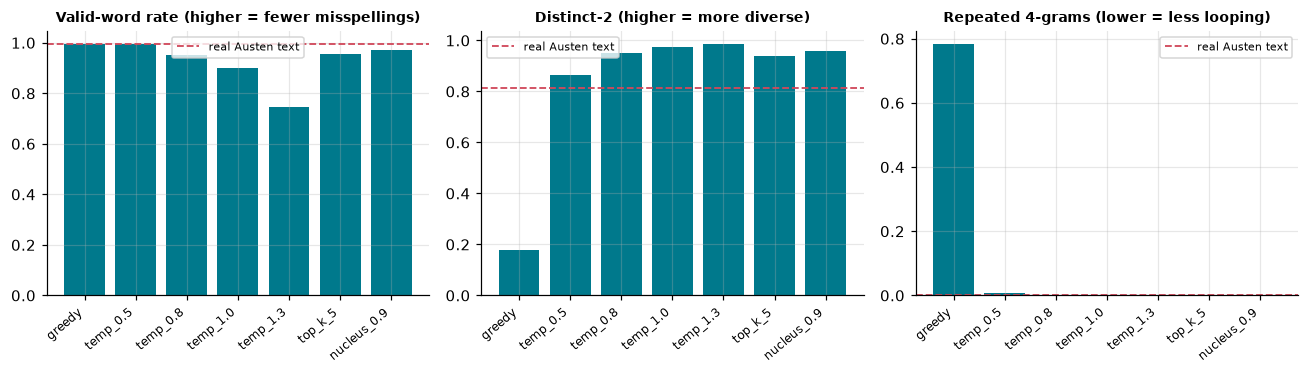

,strategy,valid_word_rate,distinct_1,distinct_2,repeat_4gram_rate,n_words,self_nll_bpc
0,greedy,0.9962,0.1331,0.1767,0.7843,135.2500,0.8319
1,temp_0.5,0.9959,0.5072,0.8655,0.0068,162.3333,1.1142
2,temp_0.8,0.9497,0.6164,0.9522,0.0000,153.4167,1.3823
3,temp_1.0,0.8998,0.6709,0.9755,0.0000,150.6667,1.6821
4,temp_1.3,0.7439,0.8013,0.9870,0.0000,135.6667,2.3506
5,top_k_5,0.9551,0.5757,0.9383,0.0000,156.2500,1.3701
6,nucleus_0.9,0.9713,0.6124,0.9578,0.0000,158.0833,1.3614


Reference metrics on real held-out Austen text: {'valid_word_rate': 0.997, 'distinct_1': 0.26, 'distinct_2': 0.814, 'repeat_4gram_rate': 0.001, 'n_words': 3641}

=== greedy ===
It is a truth universally acknowledged to be a sense of the same time to be a servant of the same time to be a
servant of the same time to be a servant of the same time to be a servant of the same time to be a servant of
the same time to be a servant of the same time to be a servant of the same time to her and her father and her
father and her father and her own consideration of her father's consideration of her fath

=== temp_0.5 ===
It is a truth universally acknowledged as soon as the time to observe it. I think the first manner of her
power, and she was a great deal to consider her and her door. She had good to the whole of the promise; and
the strong employed her own than her that had been a great deal of giving us to say to her to a subject which
had been a sort of attention, and the gratitude of the subje

In [12]:
samp = json.loads((ROOT / "results/sampling.json").read_text())
fig, sdf = A.fig_sampling(samp); plt.show()
display(sdf)
print("Reference metrics on real held-out Austen text:", {k: round(v, 3) for k, v in samp["reference_test_text"].items()})
for k, v in samp["examples"].items():
    print(f"\n=== {k} ===\n" + textwrap.fill(v[:420], 110))

### 5.6 Interactive generation with the best model

In [13]:
from src.generate import sample
ck = torch.load(ROOT / f"checkpoints/{best_run.Run}.pt"); c = ck["config"]
best_model = CharRNN(meta["vocab_size"], c["cell"], c["emb_dim"], c["hidden"], c["layers"], c["dropout"])
best_model.load_state_dict(ck["state_dict"])
for prompt in ["Elizabeth looked at him", "\"I cannot think"]:
    txt, _ = sample(best_model, stoi, itos, prompt, n=400, temperature=0.8, seed=7)
    print(textwrap.fill(txt, 110), "\n")

Elizabeth looked at him in provided by the seemed so happy for all the rest of good happiness. The manner in
her answer and acquainted and an hour as her country to side him.  "That continued into it, you have a great
man, if you would have thought of place, and some time which she ought to defer thachous of right. I rejoire
to be am sure, indeed, which she had liked for her barnet, darting about the other comfortable c 

"I cannot think it provided by the seemed so ball. Her impident that he take--the Miss Dashwoods had been long
in love standed all the character, could feel side him.  "That continued into it, you have a great man, if you
would have thought of place, and some time which she ought to defer thachous of right. I rejoire to be am
sure, indeed, which she had liked for her barnet, darting about the other comfortable c 



## 6. Summary
The conclusions are written in the report from the tables above; the key numbers are printed below for reference.

In [14]:
summary = {
    "best_model": best_run.Run, "best_test_bpc": float(best_run["Test BPC"]), "best_test_ppl": float(best_run["Test PPL"]),
    "rnn_test_bpc": float(e1.loc[e1.Cell == "RNN", "Test BPC"].iloc[0]),
    "gru_test_bpc": float(e1.loc[e1.Cell == "GRU", "Test BPC"].iloc[0]),
    "lstm_test_bpc": float(e1.loc[e1.Cell == "LSTM", "Test BPC"].iloc[0]),
    "best_ngram_test_bpc": float(best_ng), "unigram_entropy": float(H),
}
(ROOT / "results/summary.json").write_text(json.dumps(summary, indent=1)); summary

{'best_model': 'E1_gru',
 'best_test_bpc': 1.585,
 'best_test_ppl': 3.0,
 'rnn_test_bpc': 1.7661,
 'gru_test_bpc': 1.585,
 'lstm_test_bpc': 1.7261,
 'best_ngram_test_bpc': 1.6528678219418642,
 'unigram_entropy': 4.410801715500762}